In [28]:
#import library
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

#loading dataset
dataset = load_dataset('lukebarousse/data_jobs')
df=dataset['train'].to_pandas()

#data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [29]:
df_USA  = df[df['job_country']=='United States'].copy()

In [30]:
df_USA['job_Posted_month'] = df_USA['job_posted_date'].dt.strftime('%B')

In [31]:
df_USA_pivot = df_USA.pivot_table(index='job_Posted_month', columns='job_title_short', aggfunc='size')

In [32]:
df_USA_pivot.reset_index(inplace=True)
df_USA_pivot['month_number'] = pd.to_datetime(df_USA_pivot['job_Posted_month'], format='%B').dt.month 

df_USA_pivot.sort_values(by='month_number', inplace=True)
df_USA_pivot.set_index('job_Posted_month', inplace=True)

df_USA_pivot.drop(columns='month_number', inplace=True)

In [33]:
df_USA_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_Posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


<Axes: xlabel='job_Posted_month'>

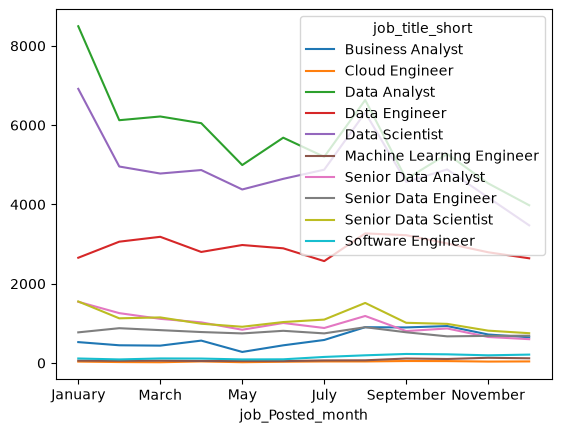

In [35]:

df_USA_pivot.plot(kind='line')

In [39]:
top_3 = df_USA['job_title_short'].value_counts().head(3).index.tolist()

top_3

['Data Analyst', 'Data Scientist', 'Data Engineer']

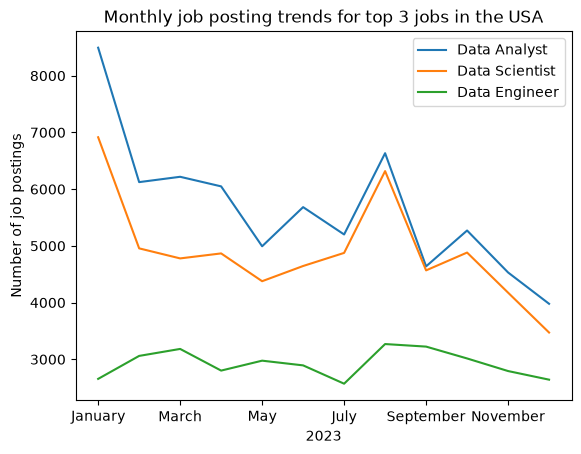

In [44]:
df_USA_pivot[top_3].plot(kind='line')
plt.title('Monthly job posting trends for top 3 jobs in the USA')
plt.xlabel('2023')
plt.ylabel('Number of job postings')
plt.legend()
plt.show()